TODO :
- Decide what one row represents and write it down (for example: a repository, a film, a weather station, or an article). As Exercises 6 and 7 showed, this choice determines what your clusters mean.

    - A row is a game. Our features are the share of the game's clips created in each hour of the day (UTC), like the zone profiles in Exercise 7 of the lab

- Build the feature table X. The table below suggests features for each project source. Use one-hot encoding for categories, take the log of skewed counts, and use TF-IDF for text columns.

- Standardise the features ((feat - feat.mean()) / feat.std()), then cluster for two or three values of 𝑘. If you compute silhouette scores on more than a few thousand rows, pass sample_size=10_000 to silhouette_score so that the 𝑂(𝑛2) pairwise distance calculation does not hang.

- Print the cluster profile table and give every cluster a short descriptive name. Put the cluster names and interpretation in your report, and the full profile table in the appendix.

- Inspect any small or hard-to-name cluster. As with the 14 broken-meter trips in Exercise 6, an unusual cluster often reveals a data-quality issue missed in the previous weeks.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.width", 100)
sns.set_theme(style="whitegrid")

CLEAN_DATA_DIR = Path.cwd().parent / "data/clean/"

clean_games_path = CLEAN_DATA_DIR / "games_cleaned.parquet"
clean_clips_path = CLEAN_DATA_DIR / "clips_cleaned.parquet"
clean_channels_path = CLEAN_DATA_DIR / "channels_cleaned.parquet"

cgdf = pd.read_parquet(clean_games_path)
cdf = pd.read_parquet(clean_clips_path)
chdf = pd.read_parquet(clean_channels_path)

### Feature selection

First we decide what one row represents. Clustering the clips one by one gave weak results, so here we change the row, as in Exercise 7 of the lab: one row is a game.

For each game we compute 24 features: the share of its clips created in each hour of the day (UTC). Two games are close if their clips are created at the same times of day. We use shares (each row sums to 1) because we collected 100 clips per game, so the number of clips says nothing about the game.

Language, number of clips and views are not used for the clustering. We keep them to describe the clusters afterwards.

## Building the feature table

In [2]:
game_map = dict(zip(cgdf["id"], cgdf["name"]))
cdf["game_name"] = cdf["game_id"].map(game_map).fillna("unknown_" + cdf["game_id"].astype(str))
cdf["hour"] = pd.to_datetime(cdf["created_at"], utc=True).dt.hour

# share of each game's clips created in each hour (rows sum to 1)
X = pd.crosstab(cdf["game_name"], cdf["hour"], normalize="index").reindex(columns=range(24), fill_value=0)

print(f"Feature matrix X shape: {X.shape}")
print(X.round(2).iloc[:5, :12])

Feature matrix X shape: (20, 24)
hour               0     1     2     3     4     5     6     7     8     9     10    11
game_name                                                                              
AION 2           0.03  0.01  0.00  0.00  0.01  0.00  0.00  0.00  0.00  0.00  0.01  0.01
Among Us         0.04  0.04  0.00  0.00  0.04  0.08  0.00  0.00  0.00  0.00  0.00  0.00
Counter-Strike   0.02  0.01  0.03  0.00  0.00  0.00  0.00  0.00  0.02  0.02  0.03  0.04
Dota 2           0.01  0.01  0.01  0.01  0.03  0.02  0.01  0.03  0.01  0.02  0.03  0.05
EA Sports FC 27  0.03  0.04  0.02  0.01  0.01  0.00  0.00  0.01  0.00  0.01  0.03  0.05


### Describing the games

These columns are not used for the clustering. The mean hour is the circular mean, so that 23h and 1h are close.

In [28]:
hours = np.arange(24)
sin_h, cos_h = np.sin(2 * np.pi * hours / 24), np.cos(2 * np.pi * hours / 24)

def circ_mean(profiles):
    ang = np.arctan2(profiles @ sin_h, profiles @ cos_h) % (2 * np.pi)
    return pd.Series(ang * 24 / (2 * np.pi), index=profiles.index if hasattr(profiles, "index") else None)

lang = pd.crosstab(cdf["game_name"], cdf["language"], normalize="index")
lang_cols = [f"lang_{l}" for l in cdf["language"].value_counts().index[:4]]
#remove from cdf unknown games
cdf = cdf[cdf["game_name"] != "unknown_510218"]
desc = pd.DataFrame(index=X.index)
desc["n_clips"] = cdf.groupby("game_name").size()
desc["mean_hour_utc"] = circ_mean(X.to_numpy()).set_axis(X.index).round(1)
desc["peak_hour_utc"] = X.idxmax(axis=1)
desc["views_median"] = cdf.groupby("game_name")["view_count"].median()
desc = desc.join(lang[[c[5:] for c in lang_cols]].add_prefix("lang_").round(2))

print(desc.sort_values("mean_hour_utc").to_string())

                    n_clips  mean_hour_utc  peak_hour_utc  views_median  lang_en  lang_ja  lang_ru  lang_es
game_name                                                                                                  
Street Fighter 6      100.0           11.6             13        1897.5     0.04     0.94     0.00     0.00
Rust                  100.0           12.4              9        5638.5     0.03     0.94     0.00     0.03
League of Legends      99.0           14.0             13        3381.0     0.53     0.19     0.00     0.05
VALORANT              100.0           14.6             13        9230.0     0.11     0.16     0.01     0.02
Counter-Strike        100.0           15.8             14        6995.5     0.19     0.00     0.78     0.00
IRL                   100.0           15.9             14       12182.5     0.28     0.02     0.40     0.06
Dota 2                100.0           16.9             17        3543.5     0.10     0.00     0.89     0.00
EA Sports FC 27        99.0 

In [29]:
keep = desc["n_clips"] >= 50
X, desc = X[keep], desc[keep].copy()

## Clustering

The hour shares are already on the same scale, so we do not standardise them, same as in the lab. With only 20 rows we also check how stable the clusters are across random seeds.

 k  inertia  silhouette  stability_ari
 2    0.264       0.164          0.511
 3    0.213       0.171          0.503
 4    0.172       0.181          0.628
 5    0.143       0.179          0.703
 6    0.121       0.191          0.682
 7    0.107       0.152          0.544
 8    0.090       0.170          0.711


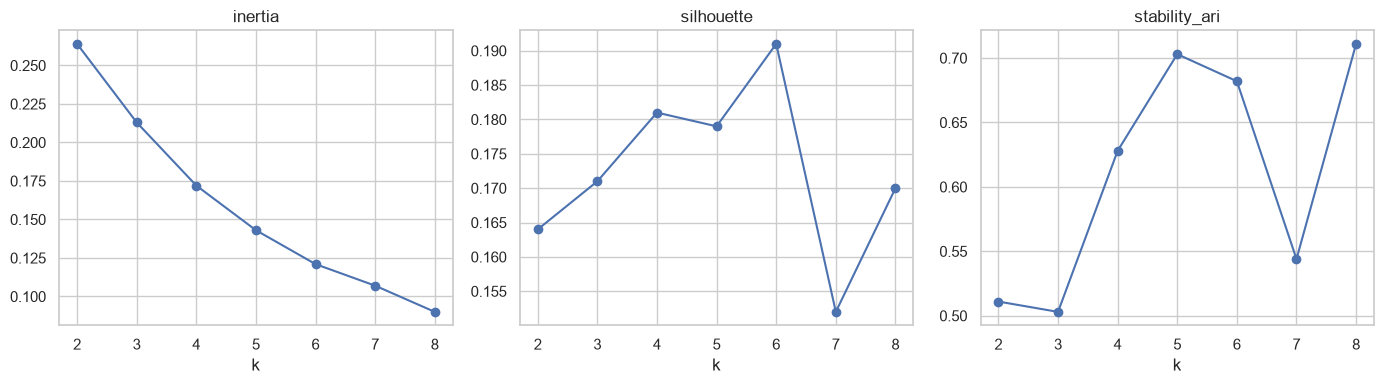

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

rows = []
for k in range(2, 9):
    fits = [KMeans(n_clusters=k, random_state=s, n_init=10).fit(X) for s in range(5)]
    ari = np.mean([adjusted_rand_score(fits[i].labels_, fits[j].labels_)
                   for i in range(5) for j in range(i + 1, 5)])
    rows.append({"k": k, "inertia": round(fits[0].inertia_, 3),
                 "silhouette": round(silhouette_score(X, fits[0].labels_), 3),
                 "stability_ari": round(ari, 3)})
summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["inertia", "silhouette", "stability_ari"]):
    ax.plot(summary_df["k"], summary_df[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

In [37]:
# Fit final model with chosen k
BEST_K = 5
kmeans = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
desc["cluster"] = kmeans.fit_predict(X)

centers = X.groupby(desc["cluster"]).mean()
profile_table = pd.DataFrame({
    "n_games": desc["cluster"].value_counts().sort_index(),
    "mean_hour_utc": circ_mean(centers.to_numpy()).set_axis(centers.index).round(1),
    "peak_hour_utc": centers.idxmax(axis=1),
    "views_median": desc.groupby("cluster")["views_median"].mean().round(0),
}).join(desc.groupby("cluster")[lang_cols].mean().round(2))

print(profile_table.to_string())
for c, g in desc.groupby("cluster"):
    print(f"\ncluster {c}: {', '.join(g.index)}")

         n_games  mean_hour_utc  peak_hour_utc  views_median  lang_en  lang_ja  lang_ru  lang_es
cluster                                                                                         
0              3           15.4             14        9469.0     0.19     0.06     0.40     0.03
1              6           19.0             23        4838.0     0.66     0.18     0.00     0.03
2              2           17.6             18        2371.0     0.45     0.00     0.04     0.17
3              5           18.5             19        9435.0     0.48     0.04     0.24     0.09
4              2           12.0             10        3768.0     0.04     0.94     0.00     0.02

cluster 0: Counter-Strike, IRL, VALORANT

cluster 1: Fortnite, Grand Theft Auto V, League of Legends, Marvel Rivals, Overwatch, Rainbow Six Siege

cluster 2: AION 2, EA Sports FC 27

cluster 3: Dota 2, Just Chatting, Minecraft, Slots, World of Warcraft

cluster 4: Rust, Street Fighter 6


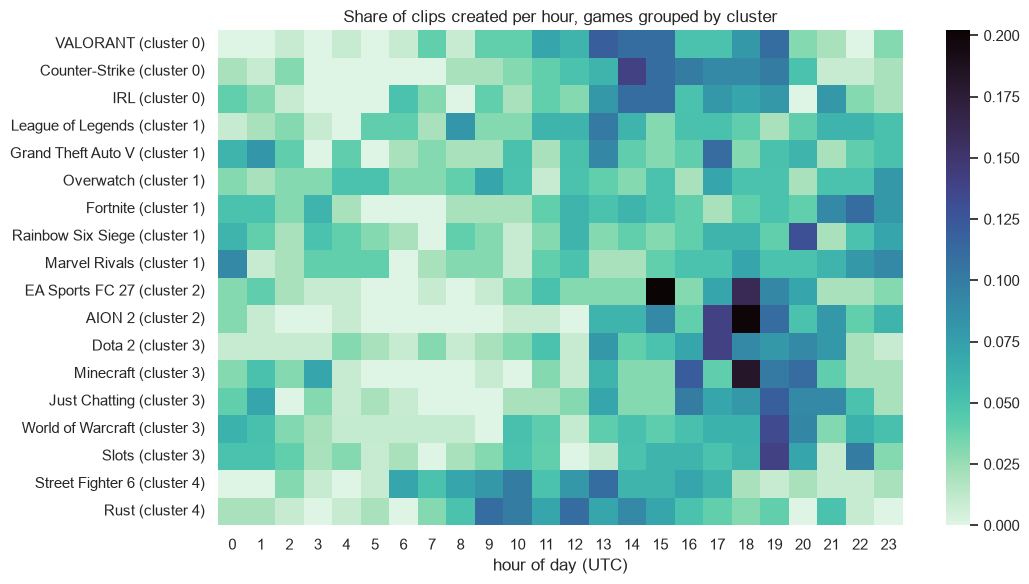

In [38]:
order = desc.sort_values(["cluster", "mean_hour_utc"]).index

plt.figure(figsize=(11, 6))
sns.heatmap(X.loc[order], cmap="mako_r",
            yticklabels=[f"{g} (cluster {desc.loc[g, 'cluster']})" for g in order])
plt.xlabel("hour of day (UTC)")
plt.ylabel("")
plt.title("Share of clips created per hour, games grouped by cluster")
plt.tight_layout()
plt.show()

In [39]:
from scipy.stats import spearmanr

for col in lang_cols:
    r, p = spearmanr(desc["mean_hour_utc"], desc[col])
    print(col, f"rho={r:+.2f}  p={p:.3g}")

lang_en rho=+0.78  p=0.000122
lang_ja rho=-0.55  p=0.0185
lang_ru rho=-0.09  p=0.729
lang_es rho=+0.24  p=0.338


### Robustness

Each game has about 100 clips, so its hour profile is noisy. We check two things: the clusters with 3-hour bins instead of 24 hours, and the clusters when the clips of each game are resampled with replacement (30 times).

In [40]:
X3 = X.T.groupby(np.arange(24) // 3).sum().T
labels3 = KMeans(n_clusters=BEST_K, random_state=42, n_init=10).fit_predict(X3)
print("ARI, 24 hours vs 3-hour bins:", round(adjusted_rand_score(desc["cluster"], labels3), 3))

boot_ari = []
for b in range(30):
    boot = cdf.groupby("game_name").sample(frac=1, replace=True, random_state=b).reset_index(drop=True)
    Xb = pd.crosstab(boot["game_name"], boot["hour"], normalize="index").reindex(index=X.index, columns=range(24), fill_value=0)
    boot_ari.append(adjusted_rand_score(desc["cluster"], KMeans(n_clusters=BEST_K, random_state=42, n_init=10).fit_predict(Xb)))
print(f"ARI against bootstrap resamples: mean={np.mean(boot_ari):.3f}  min={np.min(boot_ari):.3f}")

ARI, 24 hours vs 3-hour bins: 0.677
ARI against bootstrap resamples: mean=0.416  min=0.083


## Evaluation

### Design

One row is a game. The 24 features are the share of the game's clips created in each hour of the day (UTC), as in the zone profiles of Exercise 7. Language, number of clips and views are only used to describe the clusters. We cluster 18 games: we removed Among Us (26 clips) and `unknown_510218` (the 73 clips whose game id is not in the games table), see Data quality.

Before this we clustered the clips one by one (views relative to the game, hour of the day, channel tags and title embeddings). Those results were weak: the "top performers" cluster was just the upper quarter of the views (95.8% agreement with a simple threshold), the hour of the day had no effect on the views (epsilon squared 0.006), and the title embeddings had a silhouette close to 0 for any k. That is why we changed the row to the game.

### Choice of k

The silhouette stays between 0.15 and 0.19 for every k from 2 to 8, the stability across seeds (ARI) between 0.50 and 0.71, and the inertia decreases smoothly (0.264 to 0.090). There is no elbow and the silhouette does not favour any k, so the choice is a judgement and not a result.

We keep k = 5. The stability is low for k = 2 and k = 3 (0.51 and 0.50), 0.63 for k = 4, and 0.70 for k = 5. k = 6 has a higher silhouette (0.191) and the same stability (0.68), and k = 8 has a similar stability (0.71), but both leave about two to three games per cluster, which k = 5 already does for two of its clusters. The silhouette of k = 5 (0.179) is low: the clusters are not well separated, which is also what the heatmap and the correlation with the language show (see below).

Among Us (26 clips) was removed because with it the k-means isolated this game alone: its hour profile is very irregular, so it was a sample size problem and not a kind of game.

### Clusters (k = 5)

| Cluster | Name | Games | Mean hour (UTC) | Peak hour | Median views | EN | JA | RU | ES |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 4 | Early-hour, Japanese games | 2 | 12.0 | 10 | 3,768 | 0.04 | 0.94 | 0.00 | 0.02 |
| 0 | Afternoon games, more Russian | 3 | 15.4 | 14 | 9,469 | 0.19 | 0.06 | 0.40 | 0.03 |
| 2 | Mid-evening, lower views, more Spanish | 2 | 17.6 | 18 | 2,371 | 0.45 | 0.00 | 0.04 | 0.17 |
| 3 | Evening games, mixed languages | 5 | 18.5 | 19 | 9,435 | 0.48 | 0.04 | 0.24 | 0.09 |
| 1 | Late and spread-out games, English and Japanese | 6 | 19.0 | 23 | 4,838 | 0.66 | 0.18 | 0.00 | 0.03 |

The language columns are the share of clips in the language (mean over the games of the cluster) and the median views is the mean of the medians of each game.

- **Cluster 4:** Rust and Street Fighter 6, both 94% Japanese, with the earliest clips (mean 12.4h and 11.6h). It is the clearest cluster.
- **Cluster 0:** Counter-Strike, IRL and VALORANT, with clips around 14h to 16h. It has the most Russian clips (0.40, from Counter-Strike with 0.78 and IRL with 0.40) and views that are similar across its games (7,000 to 12,000).
- **Cluster 2:** AION 2 and EA Sports FC 27. The mean hour is 17.6h, there is no Japanese, and the Spanish share is the highest of the table (0.17). The mean of the median views is the lowest (2,371), but it comes from AION 2 (802), since EA Sports FC 27 has 3,940. With two games we read it as a description and not as a type of game.
- **Cluster 3:** Dota 2, Just Chatting, Minecraft, Slots and World of Warcraft, with a mean hour between 17h and 19h. The languages are mixed (Dota 2 is 89% Russian, World of Warcraft 90% English). The median views go from 591 (Slots) to 31,345 (Just Chatting), so the high mean (9,435) comes from one game.
- **Cluster 1:** Fortnite, Grand Theft Auto V, League of Legends, Marvel Rivals, Overwatch and Rainbow Six Siege. It is the largest and least homogeneous cluster: the mean hour of its games goes from 14.0h (League of Legends) to 20.6h (Marvel Rivals), and its profile peaks at 23h. It is mostly English (0.66), and it is the cluster with the most Japanese outside cluster 4 (0.18, mostly from Grand Theft Auto V and Overwatch, with 43% and 47%).

The views are not what separates the clusters: the median views of clusters 0 and 3 are the same (about 9,400), and inside cluster 3 they differ by a factor of 50. As in the clip-level analysis, the hour of the day does not say much about the views.

### The hour of the day follows the language

The mean hour of the clips goes from 11.6h (Street Fighter 6) to 20.6h (Marvel Rivals), and it follows the language of the clips. The Spearman correlation with the share of English clips is +0.78 (p = 0.0001), with Japanese -0.55 (p = 0.019), with Russian -0.09 (p = 0.73) and with Spanish +0.24 (p = 0.34). The Japanese games (Street Fighter 6 and Rust) are the earliest, the Russian ones (Counter-Strike and Dota 2) are in the middle, and the English ones (Rainbow Six Siege, Fortnite, World of Warcraft) are the latest.

A reasonable reading is that the hour a clip is created follows the time zone of the audience. We cannot check it with this data: the hour is in UTC and the language is the one declared by the channel. With 18 games the p-values are only indicative, since the hour profiles are noisy (see Robustness).

This is the main result of the notebook. The five clusters cut this gradient into parts (early Japanese, afternoon, mid-evening, evening, late English) and should be read as a description of it and not as separate groups. The Russian games show it: Counter-Strike is in cluster 0 and Dota 2 in cluster 3, about one hour apart (15.8h and 16.9h).

### Robustness

Two checks, both with k = 5 (see the code above).

- **3-hour bins instead of 24 hours:** ARI 0.68 with the original clusters. Most of the structure comes from the broad time of day, but some games change cluster when the hour profile is smoothed.
- **Resampling the clips of each game 30 times:** the ARI with the original clusters is 0.42 on average (minimum 0.08). With about 100 clips per game, the cluster of a single game is not reproducible, and in the worst resamples it is close to random.

What holds across both checks is the order of the games along the hour axis, and not the cluster of any particular game. The games near a boundary (for example Counter-Strike and Dota 2, or League of Legends in cluster 1 with a mean hour of 14.0h) are the ones that would change cluster first. The two clusters with two games (2 and 4) are the most sensitive to the loss of one game.

### Data quality

- Among Us has 26 clips and the other games about 100, so it was isolated as a cluster of its own. We removed it.
- 73 clips (3.9%) have the game id 510218, which is not in the games table. CreatorSMP is the only game in the table without clips, so the ids may not match, but we cannot confirm it. The collection loop does not save which game was requested, which would solve this. We removed this group because we do not know which game it is and it is not stable: with k = 6 it formed a cluster of its own, and with k = 3 it was grouped with AION 2 and EA Sports FC 27.
- Some titles are empty or only punctuation (for example "." or "lol"), and they formed their own cluster in the clip-level analysis with title embeddings.

### Limitations

- The sample is the 100 most viewed clips per game in September, so everything here is about clips that were already successful.
- Hours are in UTC. We have no time zone for the broadcasters or the viewers.
- There are only 18 rows with about 100 clips each, so the hour profiles are noisy (see the bootstrap), and two clusters have only two games.
- The choice of k = 5 is supported by stability, not by a clear silhouette or elbow. The silhouette is about the same for every k.
- Removing `unknown_510218` leaves out 3.9% of the clips. If it is a game that exists in the table under another id, it is missing from the analysis.
- Language is the one declared by the channel, not the language of the title.
- We do not have the size of the channel, which probably explains a large part of the views of a clip.

### Conclusion

The clips of a game are created at different times of the day, and this goes with the language of the clips (rho = 0.78 with the share of English). With k = 5 the games split into an early Japanese group (Rust, Street Fighter 6), an afternoon group (Counter-Strike, IRL, VALORANT), a small mid-evening group with lower views and more Spanish (AION 2, EA Sports FC 27), an evening group with mixed languages and a late, spread-out group that is mostly English. This is more stable than k = 2 or k = 3 across seeds, and it keeps most of its structure with 3-hour bins, but the cluster of a single game is not reproducible across resamples. We did not find well separated groups of games: the data is better described as a gradient than as clusters. We had other negative results (the hour of the day does not change the views, the title embeddings do not form groups, the clusters of clips are mostly views thresholds) when using clips as rows.